# Khmer Handwriting Recognition 

## Evaluate the Classical CNN

In [10]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix

sys.path.insert(0, str(Path("../../src").resolve()))
from cnn_model import CnnFeatureExtractor  # noqa: E402
from config import CLASSICAL_MODELS_DIR, IMG_HEIGHT, IMG_WIDTH  # noqa: E402
from plotting import khmer_font_prop  # noqa: E402

READY_DIR = Path("../../data/3_ready/cnn_alphabet")
CONFUSION_TABLES_DIR = Path("../../results/tables/confusion_matrix")
CONFUSION_CHARTS_DIR = Path("../../results/charts/confusion_matrix")
ACCURACY_TABLES_DIR = Path("../../results/tables/accuracy")
CONFUSION_TABLES_DIR.mkdir(parents=True, exist_ok=True)
CONFUSION_CHARTS_DIR.mkdir(parents=True, exist_ok=True)
ACCURACY_TABLES_DIR.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]

df = pd.read_parquet(READY_DIR / "cleaned_dataset.parquet")

khmer_prop = khmer_font_prop()


def build_tensors(sub_df, label_map):
    flat = np.stack(sub_df["cleaned"].to_numpy())  # saved flattened -- parquet can't hold 2D arrays
    images = torch.tensor(flat.reshape(-1, IMG_HEIGHT, IMG_WIDTH), dtype=torch.float32).unsqueeze(1)
    labels = torch.tensor(sub_df["text"].map(label_map).to_numpy(), dtype=torch.long)
    return images, labels


MODEL_NAMES = [f"{n}q" for n in QUBIT_SIZES] + ["baseline"]
MODEL_FEATURES = {f"{n}q": n for n in QUBIT_SIZES}
MODEL_FEATURES["baseline"] = 64
print(f"evaluating: {MODEL_NAMES}")

evaluating: ['4q', '6q', '8q', 'baseline']


## 1. Accuracy, precision, recall, F1: on the held-out test split, straight from the CNN

In [11]:
eval_by_model = {}

for name in MODEL_NAMES:
    model_dir = CLASSICAL_MODELS_DIR / name
    with open(model_dir / "label_map.json", encoding="utf-8") as f:
        label_map = json.load(f)
    id_to_label = {v: k for k, v in label_map.items()}
    n_features = MODEL_FEATURES[name]

    model = CnnFeatureExtractor(n_features, len(label_map))
    model.load_state_dict(torch.load(model_dir / "cnn.pt", map_location="cpu"))
    model.eval()

    sub_df = df[(df["text"].isin(label_map.keys())) & (df["split"] == "test")]
    X_test, y_test = build_tensors(sub_df, label_map)
    with torch.no_grad():
        preds = model(X_test).argmax(dim=1).numpy()
    y_true = [id_to_label[i] for i in y_test.numpy()]
    y_pred = [id_to_label[i] for i in preds]

    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    with open(CONFUSION_TABLES_DIR / f"classical_classification_report_{name}.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["class", "precision", "recall", "f1-score", "support"])
        for cls, m in report.items():
            if cls == "accuracy" or not isinstance(m, dict):
                continue
            writer.writerow([cls, round(m["precision"], 4), round(m["recall"], 4), round(m["f1-score"], 4), int(m["support"])])

    eval_by_model[name] = {
        "y_true": np.array(y_true), "y_pred": np.array(y_pred),
        "report": report, "labels": sorted(label_map.keys()),
    }
    print(f"[{name}] accuracy={report['accuracy']:.4f}  macro_f1={report['macro avg']['f1-score']:.4f}")

[4q] accuracy=0.9583  macro_f1=0.9581
[6q] accuracy=0.9444  macro_f1=0.9441
[8q] accuracy=0.9444  macro_f1=0.9442
[baseline] accuracy=0.9318  macro_f1=0.9306


## 2. Confusion matrix

In [12]:
def plot_confusion(name):
    d = eval_by_model[name]
    labels = d["labels"]
    cm = confusion_matrix(d["y_true"], d["y_pred"], labels=labels)

    fig, ax = plt.subplots(figsize=(max(6, len(labels) * 0.35), max(6, len(labels) * 0.35)))
    im = ax.imshow(cm, cmap="Greens")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8, fontproperties=khmer_prop)
    ax.set_yticklabels(labels, fontsize=8, fontproperties=khmer_prop)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"Confusion matrix — classical CNN ({name})")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    fig.savefig(CONFUSION_CHARTS_DIR / f"classical_confusion_matrix_{name}.png", dpi=150)
    plt.show()

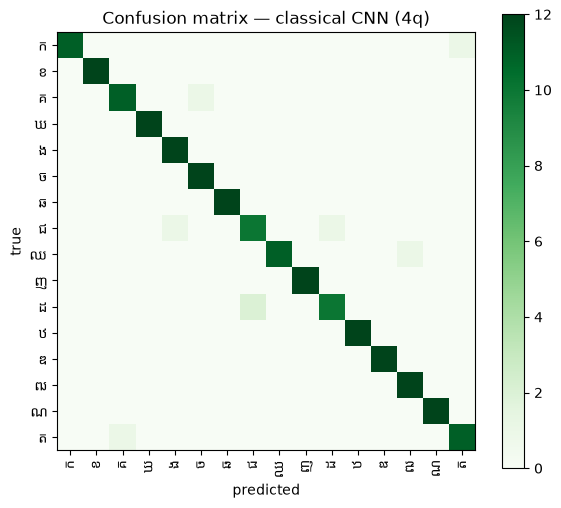

In [13]:
plot_confusion("4q")

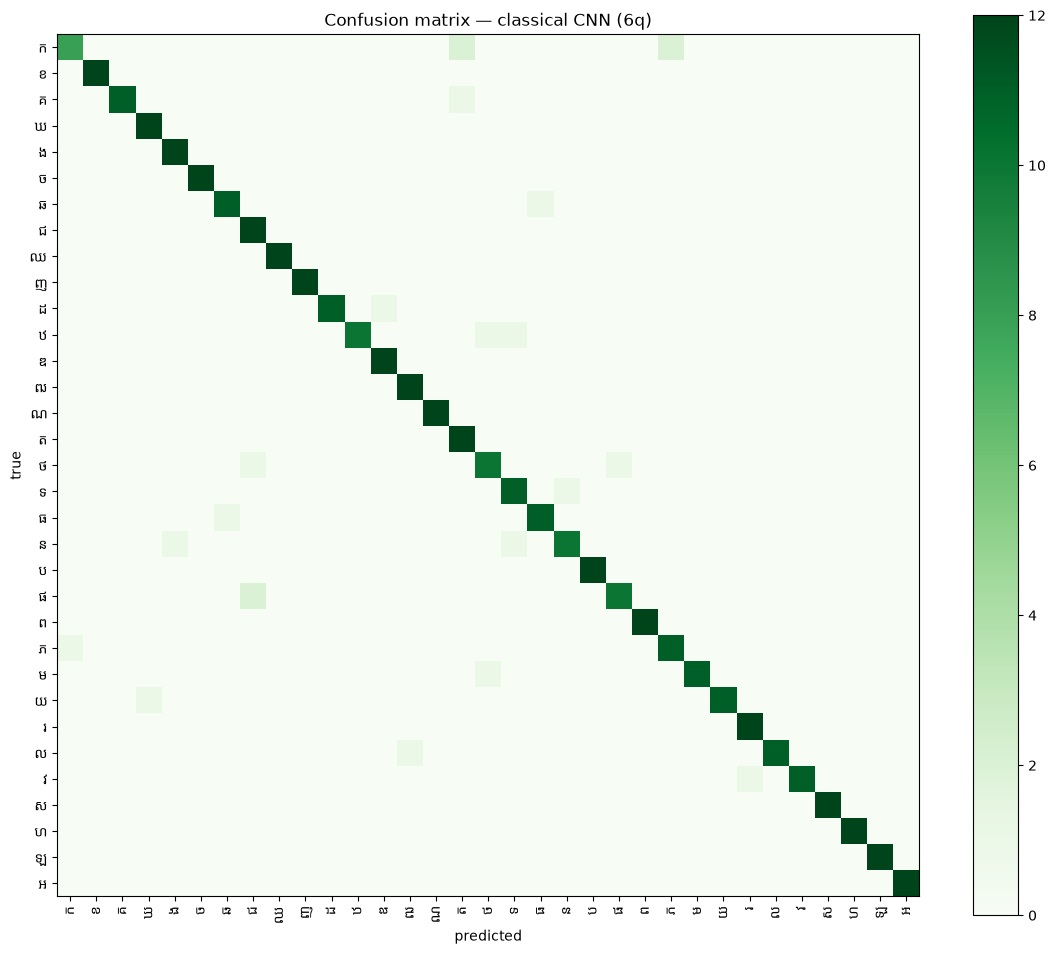

In [14]:
plot_confusion("6q")

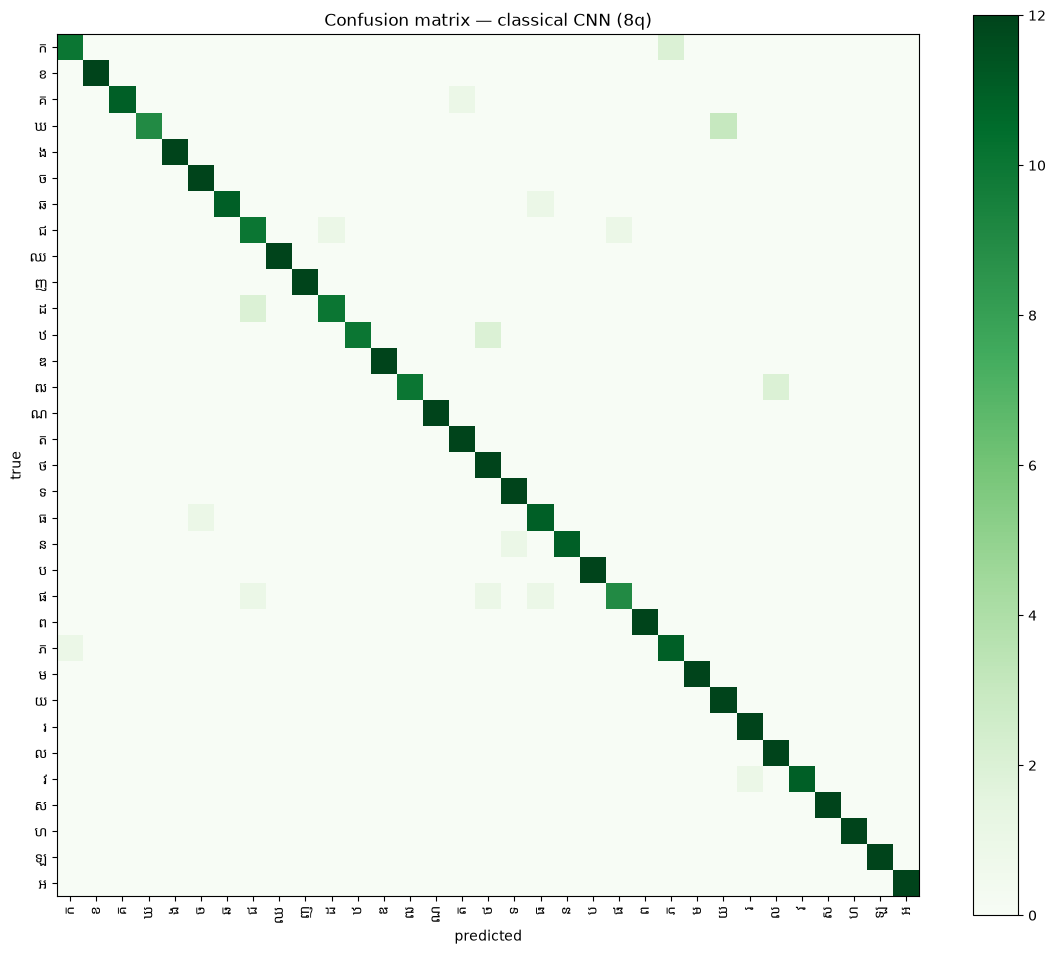

In [15]:
plot_confusion("8q")

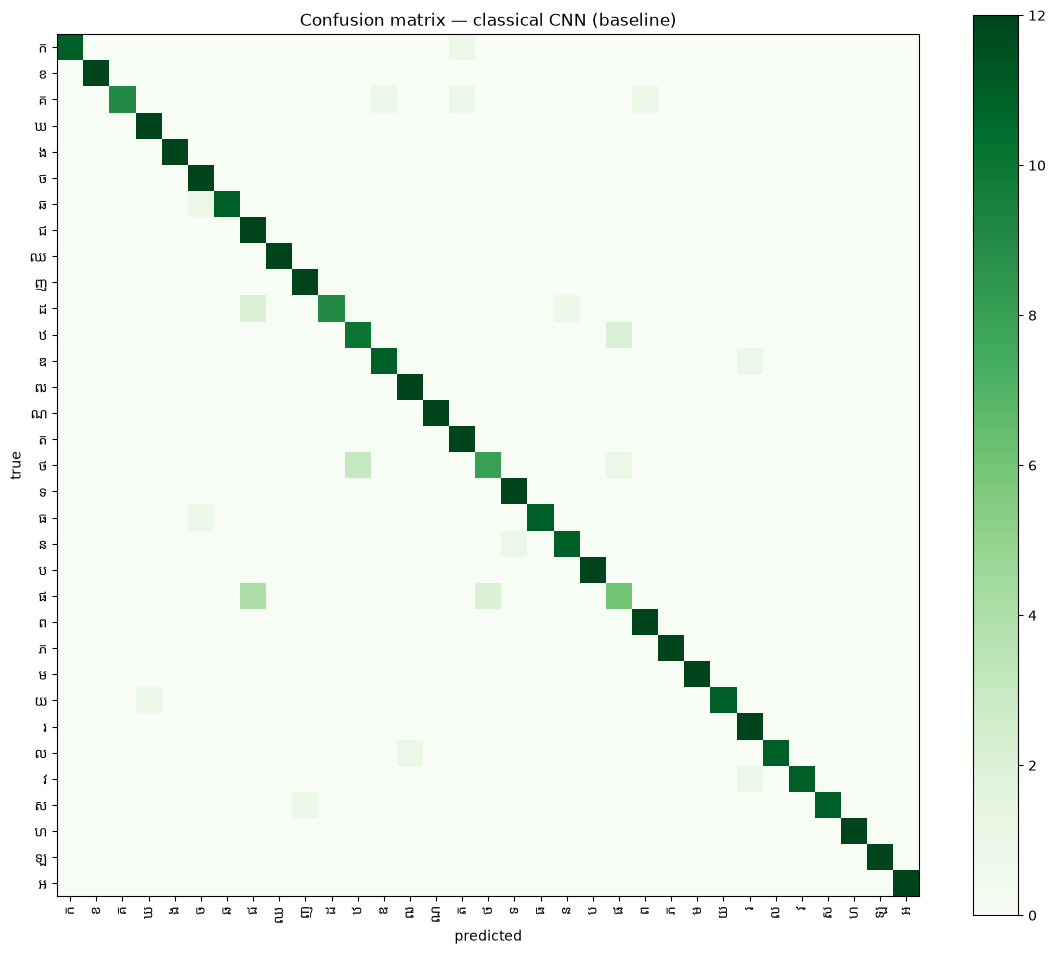

In [16]:
plot_confusion("baseline")

## 3. Summary table across all models

In [17]:
summary_rows = []
for name, d in eval_by_model.items():
    summary_rows.append({
        "model": name,
        "accuracy": round(d["report"]["accuracy"], 4),
        "macro_precision": round(d["report"]["macro avg"]["precision"], 4),
        "macro_recall": round(d["report"]["macro avg"]["recall"], 4),
        "macro_f1": round(d["report"]["macro avg"]["f1-score"], 4),
    })

with open(ACCURACY_TABLES_DIR / "classical_evaluation_summary.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0].keys()))
    writer.writeheader()
    writer.writerows(summary_rows)

print("Wrote:", ACCURACY_TABLES_DIR / "classical_evaluation_summary.csv")
pd.DataFrame(summary_rows)

Wrote: ..\..\results\tables\accuracy\classical_evaluation_summary.csv


,model,accuracy,macro_precision,macro_recall,macro_f1
0,4q,0.9583,0.9591,0.9583,0.9581
1,6q,0.9444,0.9479,0.9444,0.9441
2,8q,0.9444,0.9494,0.9444,0.9442
3,baseline,0.9318,0.9371,0.9318,0.9306
